**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:
job_name = "net_v3_50per_x4"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v3"

parameters = {
    "job_name": job_name,                           # nome di QUESTO job (i risultati escono come anomaly_results_{job_name})
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         # artifact con SAR/ e OPT/ (partNN.zip di .npy)
    "moco_version": moco_version,                   # versione del TRAINING MoCo da valutare
    "simple_proj": False,                           # questi 6 devono essere identici a quelli del training,
    "attn": False,                                  # altrimenti load_state_dict fallisce per shape diverse
    "hidden_channels_dim": 64,
    "pool_grid": 4,

    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico
    "n_normal_eval": 642,                  # serie normali usate nella valutazione (da testIdsList)
    "n_fit_series": 0,                      # serie normali per addestrare l'OC-SVM: 0 = tutte le restanti di testIdsList
    "num_anomalies": 642,
    "ocsvm_nu": 0.10,                       # quota di serie di fit lasciate fuori dal confine
    "ocsvm_gamma": "scale",                 # "scale" | "auto" | numero come stringa (es. "0.01")
    "standardize": True,                    # StandardScaler sul vettore concatenato [q; k]
    "batch_size": 16,
    "workers": 0,
    "min_flood_pct": 40.0
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "500Gi"}
    }
]

**BUILD ENVIRONMENT**

In [17]:
ad_ocsvm_func = project.new_function(
    name=f'ad_ocsvm_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:ad_ocsvm",
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1", "scikit-learn==1.5.2"]
)

build = ad_ocsvm_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-10 15:19:10,601 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f339a2a850324dd6baec3e888f2a95cb to finish...
2026-10-10 15:19:15,607 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f339a2a850324dd6baec3e888f2a95cb to finish...
2026-10-10 15:19:20,615 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f339a2a850324dd6baec3e888f2a95cb to finish...
2026-10-10 15:19:25,626 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f339a2a850324dd6baec3e888f2a95cb to finish...
2026-10-10 15:19:30,635 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f339a2a850324dd6baec3e888f2a95cb to finish...
2026-10-10 15:19:35,644 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f339a2a850324dd6baec3e888f2a95cb to finish...
2026-10-10 15:19:40,652 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f339a2a850324dd6baec3e888f2a95cb to finish...
2026-10-10 15

BUILD: COMPLETED


**TRAINING**

In [18]:
run_ad = ad_ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection OC-SVM avviato: {run_ad.id}")

2026-10-10 15:19:56,049 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...


2026-10-10 15:20:01,055 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...
2026-10-10 15:20:06,063 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...
2026-10-10 15:20:11,072 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...
2026-10-10 15:20:16,080 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...
2026-10-10 15:20:21,087 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...
2026-10-10 15:20:26,098 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...
2026-10-10 15:20:31,169 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b51a6540bbac4675a0711dc83276f228 to finish...
2026-10-10 15

Run anomaly detection OC-SVM avviato: b51a6540bbac4675a0711dc83276f228


In [4]:
RESULTS_DIR = "/tmp/anomaly_results_ocsvm"

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download("/tmp/anomaly_results_ocsvm.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

print(f"n_fit: {results['n_fit']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"OC-SVM: nu={results['ocsvm']['nu']} | gamma={results['ocsvm']['gamma']} | standardize={results['ocsvm']['standardize']} | dim={results['ocsvm']['dim']} | fuori dal confine (fit): {results['ocsvm']['frac_outside_fit']:.3f}")
print(f"score normali: {results['score_normal']['mean']:.4f} ± {results['score_normal']['std']:.4f}")
print(f"score anomale: {results['score_anom']['mean']:.4f} ± {results['score_anom']['std']:.4f}", "\n")
print(f"AUROC (score basso = anomalia): {results['auroc_ocsvm_low_anom']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_fit: 4480 | n_normali: 494 | n_anomale: 494 

OC-SVM: nu=0.05 | gamma=0.015625 | standardize=True | dim=256 | fuori dal confine (fit): 0.479
score normali: -0.0406 ± 0.0586
score anomale: -0.0944 ± 0.0269 

AUROC (score basso = anomalia): 0.785


,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
ocsvm score < 0,488.0,364.0,6.0,130.0,0.736842,0.012146,0.987854,0.57277,0.725111


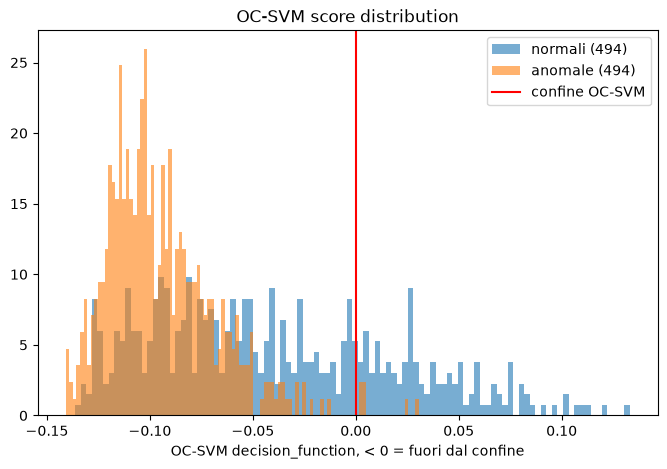

In [5]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=100, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=100, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
plt.axvline(x=0, color='r', label='confine OC-SVM')
plt.xlabel("OC-SVM decision_function, < 0 = fuori dal confine")
plt.legend()
plt.title(f"OC-SVM score distribution")
plt.show()

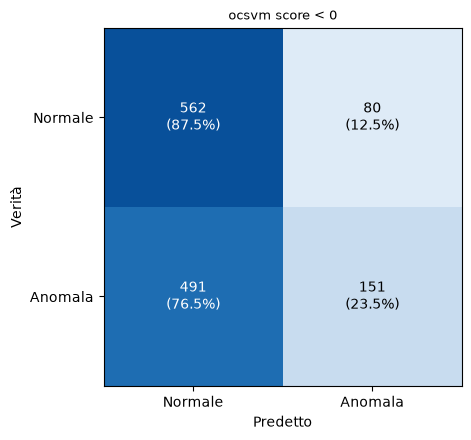

In [21]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

plt.tight_layout()
plt.show()